# Splice-site modeling and chromosome-holdout evaluation

This notebook compares simple, linear, Bayesian, and boosted-tree models for identifying splice sites. The binary models predict whether a sequence is a splice site, while the multiclass models distinguish `donor`, `acceptor`, and `none`.

The dataset includes ordinary genomic negatives and motif-centered hard negatives generated by `build_dataset.py`. A higher hard negative count will result in lower model accuracy. The final section repeats the multiclass comparison across chromosome groups to give a more reliable estimate of generalization rather than one selected split.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import label_binarize

from xgboost import XGBClassifier

import pymc as pm
import arviz as az


CORE_FEATURE_COLS = [
    "gc_content",
    "has_donor_gt",
    "has_acceptor_ag",
]

LABEL_ORDER = ["none", "donor", "acceptor"]
RANDOM_SEED = 42

## Load features



In [2]:
for candidate in ["data/processed/features.csv", "../data/processed/features.csv"]:
    if Path(candidate).exists():
        FEATURES_CSV = Path(candidate)
        break
else:
    raise FileNotFoundError(
        "couldn't find features.csv in data/processed/ from here - "
        "check your working directory, or edit the path above directly"
    )

df = pd.read_csv(FEATURES_CSV)

required_cols = {"label", "is_site", *CORE_FEATURE_COLS}
missing_cols = required_cols.difference(df.columns)
if missing_cols:
    raise ValueError(f"features.csv is missing required columns: {sorted(missing_cols)}")

if "chrom" in df.columns:
    SPLIT_COL = "chrom"
elif "contig" in df.columns:
    SPLIT_COL = "contig"
else:
    raise ValueError("features.csv needs either a 'chrom' or 'contig' column")

POSITION_COLS = [col for col in df.columns if col.startswith("pos_")]
if not POSITION_COLS:
    raise ValueError("No positional one-hot columns were found in features.csv")

FULL_FEATURE_COLS = CORE_FEATURE_COLS + POSITION_COLS

print(f"loaded {df.shape[0]} rows and {df.shape[1]} columns")
print(f"using {len(FULL_FEATURE_COLS)} predictors ({len(POSITION_COLS)} positional)")
df["label"].value_counts()


loaded 447286 rows and 334 columns
using 323 predictors (320 positional)


label
none        223643
donor       111917
acceptor    111726
Name: count, dtype: int64

## Picking which chromosome(s) to hold out

As the test genome is brewers yeast and has few splice sites, it makes it so a chromosome with too few splice sites in it makes the precision/recall/calibration plots blocky and unstable.

This table shows how many real splice sites are on each chromosome, so `TEST_CHROMS` below can be picked with actual numbers instead of a guess.

In [3]:
chrom_summary = (
    df.groupby(SPLIT_COL)
      .agg(total_rows=("is_site", "size"), positives=("is_site", "sum"))
      .sort_values("positives", ascending=False)
)
chrom_summary


,total_rows,positives
chrom,,
NC_003283.11,96328,50275
NC_003284.9,78202,37657
NC_003282.8,75284,35880
NC_003280.10,69889,35754
NC_003279.8,67367,33945
NC_003281.10,60216,30132


## Train/test split

Chromosome-based, as a random split would let near-identical sequences from the same gene land in both train and test, which can make the model look better than it is.

Edit `TEST_CHROMS` below using the table above and rerun this cell on its own whenever trying a different split - nothing above this cell needs to rerun.

In [6]:
# Aim for a ~80/20 train/test split
TEST_CHROMS = ["NC_003281.10"]

available_chroms = sorted(df[SPLIT_COL].unique())
test_chroms = [chrom for chrom in TEST_CHROMS if chrom in available_chroms]

if not test_chroms:
    raise ValueError(
        f"none of {TEST_CHROMS} found in the dataset; choose from {available_chroms}"
    )

train = df[~df[SPLIT_COL].isin(test_chroms)].copy()
test = df[df[SPLIT_COL].isin(test_chroms)].copy()

if "sequence_group" in df.columns:
    test_groups = set(test["sequence_group"])
    overlapping_rows = train["sequence_group"].isin(test_groups)
    overlap_count = int(overlapping_rows.sum())

    if overlap_count:
        train = train[~overlapping_rows].copy()
        print(
            f"removed {overlap_count} training rows whose sequences "
            "also occurred in the test set"
        )

for dataset_name, dataset in [("training", train), ("test", test)]:
    missing_labels = set(LABEL_ORDER).difference(dataset["label"].unique())

    if missing_labels:
        raise ValueError(
            f"{dataset_name} set is missing labels: {sorted(missing_labels)}. "
            "Choose different TEST_CHROMS."
        )

if train["is_site"].nunique() < 2 or test["is_site"].nunique() < 2:
    raise ValueError("Both train and test sets must contain sites and non-sites")

n_test_pos = int(test["is_site"].sum())
print(f"holding out {test_chroms}")
print(f"train: {len(train)} rows, test: {len(test)} rows ({n_test_pos} real splice sites)")
if n_test_pos < 15:
    print("test set is thin; consider adding another chromosome")


removed 85 training rows whose sequences also occurred in the test set
holding out ['NC_003281.10']
train: 386985 rows, test: 60216 rows (30132 real splice sites)


## Standardize features

Means and standard deviations are calculated from the training set only. Constant columns are left unchanged instead of producing missing values.


In [7]:
train_means = train[FULL_FEATURE_COLS].mean()
train_stds = train[FULL_FEATURE_COLS].std().replace(0, 1)

X_train_z = (train[FULL_FEATURE_COLS] - train_means) / train_stds
X_test_z = (test[FULL_FEATURE_COLS] - train_means) / train_stds

y_train = train["is_site"].to_numpy()
y_test = test["is_site"].to_numpy()


In [8]:
def evaluate(y_true, y_pred, y_score, name):
    """Calculate classification metrics for one model.
    Parameters
    ----------
    y_true : array-like
        Observed binary labels.
    y_pred : array-like
        Predicted binary labels.
    y_score : array-like
        Prediction scores or probabilities.
    name : str
        Model name displayed in the output.
    Returns
    -------
    tuple
        Metric dictionary and precision-recall curve values.
    """
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
    pr_auc = auc(recall_curve, precision_curve)
    print(
        f"{name}: precision={precision:.3f}  recall={recall:.3f}  "
        f"f1={f1:.3f}  pr_auc={pr_auc:.3f}"
    )
    metrics = {
        "model": name,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "pr_auc": pr_auc,
    }
    return metrics, (precision_curve, recall_curve)


def brier_score(y_true, prob_pred):
    """Calculate mean squared error for predicted probabilities.

    Parameters
    ----------
    y_true : array-like
        Observed binary labels.
    prob_pred : array-like
        Predicted probabilities.

    Returns
    -------
    float
        Brier score.
    """
    return np.mean((np.asarray(prob_pred) - np.asarray(y_true)) ** 2)


## Model 1: canonical-motif baseline

This rule predicts a splice site whenever the centered sequence contains the canonical donor `GT` motif or acceptor `AG` motif.

Because the dataset now includes motif-centered hard negatives, this is a meaningful baseline rather than a nearly complete solution: it measures how well the two central bases perform without using the surrounding sequence.


In [9]:
baseline_score = test[["has_donor_gt", "has_acceptor_ag"]].max(axis=1)
baseline_pred = baseline_score.astype(int)
row_baseline, (p1, r1) = evaluate(
    y_test,
    baseline_pred,
    baseline_score,
    "Canonical motif rule",
)


Canonical motif rule: precision=0.652  recall=0.994  f1=0.788  pr_auc=0.825


## Model 2: logistic regression

This binary model uses GC content, the two motif indicators, and every positional one-hot feature. It tests whether the surrounding sequence improves site-versus-non-site prediction beyond the canonical-motif rule.


In [10]:
sk_model = LogisticRegression(max_iter=2000)
sk_model.fit(X_train_z[FULL_FEATURE_COLS], y_train)
sk_prob = sk_model.predict_proba(X_test_z[FULL_FEATURE_COLS])[:, 1]
sk_pred = sk_model.predict(X_test_z[FULL_FEATURE_COLS])
row_lr, (p2, r2) = evaluate(y_test, sk_pred, sk_prob, "Logistic regression")


Logistic regression: precision=0.861  recall=0.914  f1=0.886  pr_auc=0.928


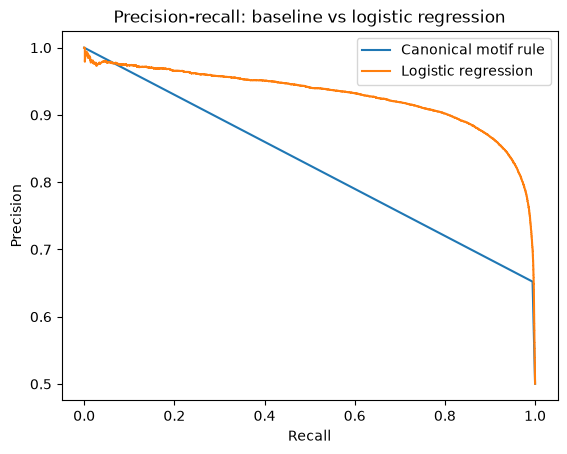

In [11]:
fig, ax = plt.subplots()
ax.plot(r1, p1, label="Canonical motif rule")
ax.plot(r2, p2, label="Logistic regression")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall: baseline vs logistic regression")
ax.legend()
plt.show()


## Model 3: Bayesian logistic regression

The Bayesian model uses the three compact sequence features: GC content and the two canonical-motif indicators. Keeping this model compact makes posterior sampling practical and its coefficients easy to interpret.


In [45]:
N_SUBSAMPLE_PER_CLASS = 5000

pos_idx = train.index[y_train == 1]
neg_idx = train.index[y_train == 0]
rng = np.random.default_rng(RANDOM_SEED)
sub_pos = rng.choice(pos_idx, size=min(len(pos_idx), N_SUBSAMPLE_PER_CLASS), replace=False)
sub_neg = rng.choice(neg_idx, size=min(len(neg_idx), N_SUBSAMPLE_PER_CLASS), replace=False)
sub_idx = np.concatenate([sub_pos, sub_neg])

X_fit = X_train_z.loc[sub_idx, CORE_FEATURE_COLS].to_numpy()
y_fit = train.loc[sub_idx, "is_site"].to_numpy()
print(f"fitting on {len(sub_idx)} rows ({sub_pos.size} positive, {sub_neg.size} negative)")


fitting on 10000 rows (5000 positive, 5000 negative)


In [46]:
with pm.Model():
    intercept = pm.Normal("intercept", mu=0, sigma=2)
    beta_gc = pm.Normal("beta_gc", mu=0, sigma=2)
    beta_donor = pm.Normal("beta_donor", mu=0, sigma=2)
    beta_acceptor = pm.Normal("beta_acceptor", mu=0, sigma=2)

    logit_p = (
        intercept
        + beta_gc * X_fit[:, 0]
        + beta_donor * X_fit[:, 1]
        + beta_acceptor * X_fit[:, 2]
    )
    p = pm.math.invlogit(logit_p)
    pm.Bernoulli("y_obs", p=p, observed=y_fit)

    idata = pm.sample(draws=1000, tune=1000, chains=2, random_seed=RANDOM_SEED)

az.summary(idata, var_names=["intercept", "beta_gc", "beta_donor", "beta_acceptor"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [intercept, beta_gc, beta_donor, beta_acceptor]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 4 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,0.016,0.021,-0.021,0.060,0.000,0.0,3022.0,1187.0,1.0
beta_gc,-0.167,0.022,-0.210,-0.128,0.000,0.0,2865.0,1564.0,1.0
beta_donor,0.709,0.024,0.664,0.756,0.001,0.0,1625.0,1514.0,1.0
beta_acceptor,0.740,0.024,0.694,0.783,0.001,0.0,1745.0,1475.0,1.0


`r_hat` should be close to 1.0 for every parameter above. If any are noticeably higher, the chains didn't agree with each other and this fit shouldn't be trusted yet - rerunning with more `tune`/`draws`, or checking the input features for something odd, would be the next step.

In [47]:
posterior = idata.posterior
intercept_s = posterior["intercept"].values.flatten()
beta_gc_s = posterior["beta_gc"].values.flatten()
beta_donor_s = posterior["beta_donor"].values.flatten()
beta_acceptor_s = posterior["beta_acceptor"].values.flatten()

X_test_arr = X_test_z[CORE_FEATURE_COLS].to_numpy()
logits = (
    intercept_s[:, None]
    + beta_gc_s[:, None] * X_test_arr[:, 0][None, :]
    + beta_donor_s[:, None] * X_test_arr[:, 1][None, :]
    + beta_acceptor_s[:, None] * X_test_arr[:, 2][None, :]
)
probs = 1 / (1 + np.exp(-logits))

bayes_mean_prob = probs.mean(axis=0)
bayes_lower = np.percentile(probs, 2.5, axis=0)
bayes_upper = np.percentile(probs, 97.5, axis=0)
bayes_pred = (bayes_mean_prob > 0.5).astype(int)

row_bayes, (p3, r3) = evaluate(
    y_test,
    bayes_pred,
    bayes_mean_prob,
    "Bayesian logistic regression",
)


Bayesian logistic regression: precision=0.686  recall=0.851  f1=0.760  pr_auc=0.610


## Sanity check: naive baseline

This compares both probability models with always predicting the training set's positive rate. A useful probability model should have a lower Brier score.


In [48]:
naive_prob = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)
naive_brier = brier_score(y_test, naive_prob)
sk_brier = brier_score(y_test, sk_prob)
bayes_brier = brier_score(y_test, bayes_mean_prob)

print(f"naive baseline:                       brier={naive_brier:.3f}")
print(f"Logistic regression:                  brier={sk_brier:.3f}")
print(f"Bayesian logistic regression:         brier={bayes_brier:.3f}")

for name, score in [
    ("Logistic regression", sk_brier),
    ("Bayesian logistic regression", bayes_brier),
]:
    if score > naive_brier:
        print(f"{name} is worse than the naive baseline; check the held-out chromosomes")

row_lr["brier_score"] = sk_brier
row_bayes["brier_score"] = bayes_brier
row_baseline["brier_score"] = np.nan


naive baseline:                       brier=0.250
Logistic regression:                  brier=0.088
Bayesian logistic regression:         brier=0.210


## Results table

The motif rule does not produce calibrated probabilities, so its Brier score is left blank.


In [49]:
results_df = pd.DataFrame([row_baseline, row_lr, row_bayes])
results_df

,model,precision,recall,f1,pr_auc,brier_score
0,Canonical motif rule,0.652171,0.994425,0.787728,0.824693,NaN
1,Logistic regression,0.860649,0.913547,0.886309,0.928424,0.088081
2,Bayesian logistic regression,0.685792,0.851254,0.759617,0.610406,0.210254


By the nature of the model, the Bayesian logistic regression is heavily effected by the hard negative fraction of our negative types.

## Example predictions with uncertainty

Picking the test rows with the *widest* credible intervals on purpose, not a random sample - that's where a plain probability and a probability-with-uncertainty actually look different from each other. A random sample would mostly show confident, easy cases and undersell the point of doing this.

In [38]:
interval_width = bayes_upper - bayes_lower
widest_idx = np.argsort(interval_width)[::-1][:8]

examples = pd.DataFrame({
    "true_label": y_test[widest_idx],
    "sklearn_lr_prob": sk_prob[widest_idx].round(3),
    "bayesian_mean_prob": bayes_mean_prob[widest_idx].round(3),
    "bayesian_95pct_lower": bayes_lower[widest_idx].round(3),
    "bayesian_95pct_upper": bayes_upper[widest_idx].round(3),
})
examples

,true_label,sklearn_lr_prob,bayesian_mean_prob,bayesian_95pct_lower,bayesian_95pct_upper
0,0,0.626,0.347,0.320,0.376
1,0,0.121,0.385,0.357,0.413
2,0,0.839,0.390,0.363,0.417
3,0,0.004,0.357,0.331,0.384
4,0,0.036,0.395,0.369,0.422
5,0,0.025,0.395,0.369,0.422
6,0,0.214,0.395,0.369,0.422
7,0,0.003,0.395,0.369,0.422


## Calibration

Bins predicted probabilities and checks how often those predictions were actually right, compared to the diagonal (perfect calibration).

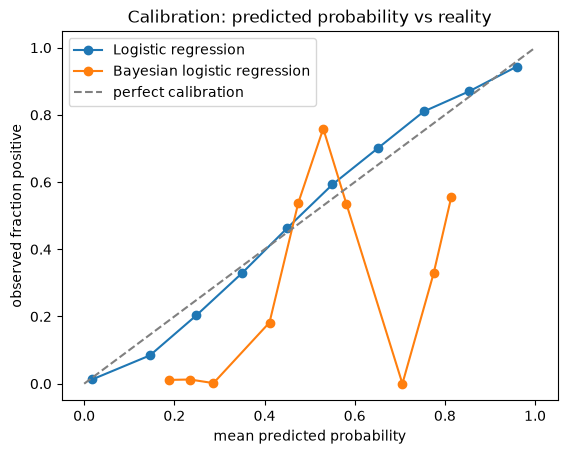

In [39]:
fig, ax = plt.subplots()
for name, prob in [("Logistic regression", sk_prob), ("Bayesian logistic regression", bayes_mean_prob)]:
    bins = pd.cut(prob, bins=10, include_lowest=True)
    calib = (
        pd.DataFrame({"prob": prob, "label": y_test, "bin": bins})
        .groupby("bin", observed=True)
        .agg(mean_predicted=("prob", "mean"), observed_rate=("label", "mean"))
        .dropna()
    )
    ax.plot(calib["mean_predicted"], calib["observed_rate"], marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="perfect calibration")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed fraction positive")
ax.set_title("Calibration: predicted probability vs reality")
ax.legend()
plt.show()

## Multiclass classification

The earlier models combine donors and acceptors into the binary `is_site` target. The following models instead predict all three original labels:

- `none`: the sequence is not an annotated splice site
- `donor`: the sequence contains the beginning of an intron
- `acceptor`: the sequence contains the end of an intron

This is the task most closely aligned with the final goal of the project. Accuracy reports the overall proportion classified correctly, while macro F1 gives each class equal importance even when their sample counts differ.


In [20]:
label_to_int = {
    label: index
    for index, label in enumerate(LABEL_ORDER)
}

y_train_multi = train["label"].map(label_to_int).to_numpy()
y_test_multi = test["label"].map(label_to_int).to_numpy()

X_train_multi = X_train_z.loc[train.index, FULL_FEATURE_COLS,]
X_test_multi = X_test_z.loc[test.index, FULL_FEATURE_COLS,]

### Model 4: multiclass logistic regression

Multiclass logistic regression estimates a probability for `none`, `donor`, and `acceptor`. It treats nucleotide-position effects as additive, making it a useful and relatively interpretable baseline.

The model is regularized by default, which helps control overfitting when the number of positional features is large relative to the number of sequences. The hard negatives test whether it learns surrounding sequence patterns instead of relying only on centered `GT` or `AG` motifs.


In [21]:
multiclass_lr = LogisticRegression(
    max_iter=3000,
    random_state=RANDOM_SEED,
)

multiclass_lr.fit(X_train_multi, y_train_multi)

multiclass_lr_pred = multiclass_lr.predict(X_test_multi)
multiclass_lr_prob = multiclass_lr.predict_proba(X_test_multi)


### Model 5: XGBoost

XGBoost combines many small decision trees. Unlike logistic regression, trees can learn interactions between positions—for example, that a base is informative only when another motif is also present.

The trees are deliberately shallow and regularized because this yeast dataset is small. Row and feature subsampling further reduce overfitting. Performance on motif-centered hard negatives indicates whether these interactions add useful information beyond the canonical splice motifs.


In [22]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(LABEL_ORDER),
    n_estimators=150,
    max_depth=2,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    eval_metric="mlogloss",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

xgb_model.fit(X_train_multi, y_train_multi)

xgb_pred = xgb_model.predict(X_test_multi)
xgb_prob = xgb_model.predict_proba(X_test_multi)


### Multiclass evaluation

The summary table compares overall accuracy and macro F1. The per-class table shows where each model succeeds or fails using precision, recall, F1, and one-versus-rest precision-recall AUC.

The confusion matrices show the exact types of errors, such as acceptors being predicted as non-sites.


In [23]:
def evaluate_multiclass(y_true, y_pred, probabilities, model_name):
    """
    Calculate overall and per-class multiclass metrics.

    Parameters
    ----------
    y_true : numpy.ndarray
        Observed integer class labels.
    y_pred : numpy.ndarray
        Predicted integer class labels.
    probabilities : numpy.ndarray
        Predicted probability for each class.
    model_name : str
        Name of the evaluated model.

    Returns
    -------
    tuple
        Overall metric dictionary and per-class metric table.
    """
    report = classification_report(
        y_true,
        y_pred,
        labels=range(len(LABEL_ORDER)),
        target_names=LABEL_ORDER,
        output_dict=True,
        zero_division=0,
    )

    binary_labels = label_binarize(
        y_true,
        classes=range(len(LABEL_ORDER)),
    )

    class_pr_auc = average_precision_score(
        binary_labels,
        probabilities,
        average=None,
    )

    overall_metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

    class_metrics = pd.DataFrame(
        {
            "model": model_name,
            "class": LABEL_ORDER,
            "precision": [
                report[label]["precision"]
                for label in LABEL_ORDER
            ],
            "recall": [
                report[label]["recall"]
                for label in LABEL_ORDER
            ],
            "f1": [
                report[label]["f1-score"]
                for label in LABEL_ORDER
            ],
            "pr_auc": class_pr_auc,
        }
    )

    return overall_metrics, class_metrics

In [21]:
lr_summary, lr_class_metrics = evaluate_multiclass(
    y_test_multi,
    multiclass_lr_pred,
    multiclass_lr_prob,
    "Multiclass logistic regression",
)

xgb_summary, xgb_class_metrics = evaluate_multiclass(
    y_test_multi,
    xgb_pred,
    xgb_prob,
    "XGBoost",
)

multiclass_results = pd.DataFrame([
    lr_summary,
    xgb_summary,
])

per_class_results = pd.concat(
    [lr_class_metrics, xgb_class_metrics],
    ignore_index=True,
)

display(multiclass_results)
display(per_class_results)

,model,accuracy,macro_f1
0,Multiclass logistic regression,0.880851,0.881232
1,XGBoost,0.906383,0.908154


,model,class,precision,recall,f1,pr_auc
0,Multiclass logistic regression,none,0.883929,0.876106,0.880000,0.934252
1,Multiclass logistic regression,donor,0.934426,0.934426,0.934426,0.979605
2,Multiclass logistic regression,acceptor,0.822581,0.836066,0.829268,0.842857
3,XGBoost,none,0.909910,0.893805,0.901786,0.955972
4,XGBoost,donor,0.966667,0.950820,0.958678,0.988115
5,XGBoost,acceptor,0.843750,0.885246,0.864000,0.944552


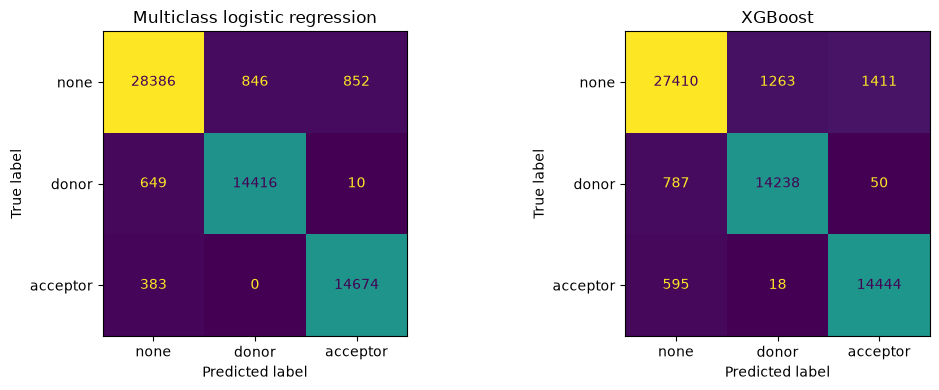

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    multiclass_lr_pred,
    display_labels=LABEL_ORDER,
    colorbar=False,
    ax=axes[0],
)

axes[0].set_title("Multiclass logistic regression")

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    xgb_pred,
    display_labels=LABEL_ORDER,
    colorbar=False,
    ax=axes[1],
)

axes[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

## Repeated chromosome-holdout evaluation

Performance from one chromosome pair may depend on which chromosomes were selected. Here, chromosomes are assigned to five roughly equal groups. Each group is used as the test set once while the remaining chromosomes form the training set.

All preprocessing is recalculated inside each fold using training data only. Exact sequences found in a test fold are also removed from that fold's training data. The comparison focuses on macro F1 because donors, acceptors, and non-sites should contribute equally to the result.


In [25]:
def build_chromosome_folds(dataframe, split_col, n_splits=5):
    """Assign chromosomes to approximately equal-sized test folds.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Feature dataset containing chromosome identifiers.
    split_col : str
        Column containing chromosome identifiers.
    n_splits : int, optional
        Number of chromosome groups, by default 5.

    Returns
    -------
    list of list of str
        Chromosome identifiers assigned to each test fold.
    """
    chromosome_sizes = dataframe.groupby(split_col).size().sort_values(ascending=False)
    folds = [[] for _ in range(n_splits)]
    fold_sizes = [0] * n_splits

    for chromosome, size in chromosome_sizes.items():
        smallest_fold = int(np.argmin(fold_sizes))
        folds[smallest_fold].append(chromosome)
        fold_sizes[smallest_fold] += int(size)

    return folds


def evaluate_chromosome_fold(dataframe, held_out_chromosomes, fold_number):
    """Train and evaluate multiclass models on one chromosome fold.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Complete feature dataset.
    held_out_chromosomes : list of str
        Chromosomes assigned to the test set.
    fold_number : int
        Display number for the fold.

    Returns
    -------
    list of dict
        Accuracy and macro-F1 results for both models.
    """
    fold_test = dataframe[dataframe[SPLIT_COL].isin(held_out_chromosomes)].copy()
    fold_train = dataframe[~dataframe[SPLIT_COL].isin(held_out_chromosomes)].copy()

    overlap_count = 0
    if "sequence_group" in dataframe.columns:
        test_groups = set(fold_test["sequence_group"])
        overlap_mask = fold_train["sequence_group"].isin(test_groups)
        overlap_count = int(overlap_mask.sum())
        fold_train = fold_train[~overlap_mask].copy()

    for name, fold_data in [("training", fold_train), ("test", fold_test)]:
        missing = set(LABEL_ORDER).difference(fold_data["label"].unique())
        if missing:
            raise ValueError(
                f"Fold {fold_number} {name} data are missing labels: {sorted(missing)}"
            )

    means = fold_train[FULL_FEATURE_COLS].mean()
    stds = fold_train[FULL_FEATURE_COLS].std().replace(0, 1)
    x_train = (fold_train[FULL_FEATURE_COLS] - means) / stds
    x_test = (fold_test[FULL_FEATURE_COLS] - means) / stds

    y_train_fold = fold_train["label"].map(label_to_int).to_numpy()
    y_test_fold = fold_test["label"].map(label_to_int).to_numpy()

    models = {
        "Multiclass logistic regression": LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_SEED,
        ),
        "XGBoost": XGBClassifier(
            objective="multi:softprob",
            num_class=len(LABEL_ORDER),
            n_estimators=150,
            max_depth=2,
            learning_rate=0.05,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="mlogloss",
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    }

    fold_results = []
    for model_name, model in models.items():
        model.fit(x_train, y_train_fold)
        predictions = model.predict(x_test)
        fold_results.append(
            {
                "fold": fold_number,
                "held_out_chromosomes": ", ".join(held_out_chromosomes),
                "model": model_name,
                "test_rows": len(fold_test),
                "removed_training_overlaps": overlap_count,
                "accuracy": accuracy_score(y_test_fold, predictions),
                "macro_f1": f1_score(y_test_fold, predictions, average="macro"),
            }
        )

    return fold_results


In [26]:
chromosome_folds = build_chromosome_folds(
    df,
    SPLIT_COL,
    n_splits=5,
)

all_holdout_results = []
for fold_number, held_out_chromosomes in enumerate(chromosome_folds, start=1):
    all_holdout_results.extend(
        evaluate_chromosome_fold(
            df,
            held_out_chromosomes,
            fold_number,
        )
    )

holdout_results = pd.DataFrame(all_holdout_results)

holdout_summary = (
    holdout_results.groupby("model")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        macro_f1_min=("macro_f1", "min"),
        macro_f1_max=("macro_f1", "max"),
    )
    .reset_index()
)

display(holdout_results)
display(holdout_summary)


,fold,held_out_chromosomes,model,test_rows,removed_training_overlaps,accuracy,macro_f1
0,1,NC_003283.11,Multiclass logistic regression,96328,80,0.945146,0.945751
1,1,NC_003283.11,XGBoost,96328,80,0.924612,0.925432
2,2,NC_003284.9,Multiclass logistic regression,78202,64,0.953774,0.953379
3,2,NC_003284.9,XGBoost,78202,64,0.928237,0.927632
4,3,NC_003282.8,Multiclass logistic regression,75284,120,0.950321,0.949650
5,3,NC_003282.8,XGBoost,75284,120,0.926053,0.925099
6,4,NC_003280.10,Multiclass logistic regression,69889,77,0.952339,0.952744
7,4,NC_003280.10,XGBoost,69889,77,0.930447,0.930947
8,5,"NC_003279.8, NC_003281.10",Multiclass logistic regression,127583,138,0.954147,0.954320
9,5,"NC_003279.8, NC_003281.10",XGBoost,127583,138,0.932013,0.932208


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,macro_f1_min,macro_f1_max
0,Multiclass logistic regression,0.951145,0.003675,0.951169,0.003499,0.945751,0.954320
1,XGBoost,0.928272,0.003043,0.928264,0.003209,0.925099,0.932208


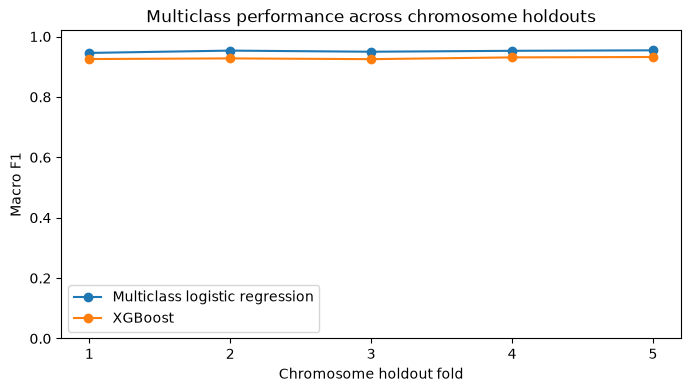

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))

for model_name, model_results in holdout_results.groupby("model"):
    ax.plot(
        model_results["fold"],
        model_results["macro_f1"],
        marker="o",
        label=model_name,
    )

ax.set_xlabel("Chromosome holdout fold")
ax.set_ylabel("Macro F1")
ax.set_title("Multiclass performance across chromosome holdouts")
ax.set_xticks(sorted(holdout_results["fold"].unique()))
ax.set_ylim(0, 1.02)
ax.legend()
plt.show()


### Interpreting the repeated holdouts

Compare both the mean and the variation across folds:

- A higher mean macro F1 indicates better average performance.
- A smaller standard deviation indicates more consistent generalization across chromosomes.
- If the difference between model means is small relative to the fold-to-fold variation, the results do not establish a clear winner.
- A particularly weak fold should be inspected for class counts, unusual sequences, or chromosome-specific biology.

These repeated results should be treated as the main model comparison. The earlier selected split remains useful for detailed confusion matrices, probability plots, and Bayesian interpretation.


## Save results

Writes to `results/` relative to wherever this notebook's working directory turned is - if that's `notebooks/`, look for a `results/` folder created alongside it rather than the project root.

In [ ]:
results_dir = FEATURES_CSV.parent.parent.parent / "results"
results_dir.mkdir(exist_ok=True)

results_df.to_csv(results_dir / "model_comparison.csv", index=False)
examples.to_csv(results_dir / "example_predictions.csv", index=False)
multiclass_results.to_csv(
    results_dir / "multiclass_model_comparison.csv",
    index=False,
)
per_class_results.to_csv(
    results_dir / "multiclass_per_class_metrics.csv",
    index=False,
)
holdout_results.to_csv(
    results_dir / "chromosome_holdout_results.csv",
    index=False,
)
holdout_summary.to_csv(
    results_dir / "chromosome_holdout_summary.csv",
    index=False,
)

print(f"saved result CSVs to {results_dir}/")
